# 02 — Tracing a sensorimotor pathway

Phase 1 turned the brain into a signed sparse matrix. This notebook asks what that matrix *does*:
how does a signal from the eyes, antennae or tongue reach the **descending neurons (DNs)**, the
~1,300 neurons that carry commands from the brain down the neck to the body? DNs are the
controller's output layer, and the interface Phase 4 will connect to a simulated fly in MuJoCo.

Two parts:
1. **Flagship circuit:** looming visual input to the giant fiber (DNp01), the fly's fastest escape.
2. **Brain-wide:** how far every sensory modality is from the DNs.

All algorithms live in `src/c2c/analysis/pathways.py` (tested in `tests/test_pathways.py`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from c2c.analysis import graph_stats as gs
from c2c.analysis import pathway_plots as pp
from c2c.analysis import pathways as pw
from c2c.data import annotations as an
from c2c.data.graph import load_graph
from c2c.paths import FIGURES, PROCESSED

gs.apply_style()
FIGURES.mkdir(parents=True, exist_ok=True)

## Load the graph and join the annotations

In [2]:
g = load_graph(PROCESSED / "graph_v783_min5.npz")
ann = an.align_to_graph(an.load_annotations(), g)   # row k describes matrix index k
an.coverage(ann)

{'graph_neurons': 134181,
 'annotated': 134171,
 'unannotated': 10,
 'fraction': 0.9999254738003145}

In [3]:
# What kinds of neurons are in the >=5-synapse graph?
ann["super_class"].value_counts(dropna=False).to_frame("neurons")

,neurons
super_class,
optic,77219
central,32294
sensory,12665
visual_projection,8031
ascending,1629
descending,1276
visual_centrifugal,519
sensory_ascending,360
motor,109


## Part 1 — Looming to escape: the giant fiber

When something approaches fast (a looming shadow, a swatter), a fly can be airborne in a few
milliseconds. The fastest route runs through the **giant fiber** (DNp01), one per side, which
drives the jump muscle in the body. Two visual projection neuron types, **LPLC2** and **LC4**,
are known to encode looming; we check what the connectome says.

In [4]:
gf = an.select(ann, cell_type="DNp01")
ann.loc[gf, ["root_id", "cell_type", "hemibrain_type", "side", "top_nt"]]

,root_id,cell_type,hemibrain_type,side,top_nt
55447,720575940622838154,DNp01,Giant Fiber,left,acetylcholine
105352,720575940632499757,DNp01,Giant Fiber,right,glutamate


Note the predicted transmitter: the right giant fiber is predicted **glutamatergic**, the left
**cholinergic**. The giant fiber is a well-studied cholinergic neuron that also uses electrical
synapses, so the right-side prediction is almost certainly wrong. That changes the sign of its
*outgoing* edges in `W` (which matter little here, since its targets are in the body, outside this
brain dataset), and it is a useful reminder that signs are predictions with error bars.

In [5]:
F = pw.input_fractions(g)        # w[i, j] = share of i's input that comes from j
edges = pw.edge_table(g)
edges["fraction"] = F.data       # same storage order as counts, so this lines up

def input_breakdown(target, labels=ann["cell_type"], top=8):
    rows = edges[edges["post"] == target].copy()
    rows["type"] = labels.to_numpy()[rows["pre"]]
    return (rows.groupby("type")
                .agg(neurons=("pre", "size"), synapses=("synapses", "sum"),
                     fraction=("fraction", "sum"), sign=("sign", "mean"))
                .sort_values("fraction", ascending=False).head(top).round(3))

for k in gf:
    print(f"giant fiber, {ann.at[k, 'side']} side")
    display(input_breakdown(k))

giant fiber, left side


,neurons,synapses,fraction,sign
type,,,,
LC4,40,329,0.088,-0.100
LPLC2,37,305,0.081,0.054
CB3707,4,293,0.078,-1.000
DNp70,2,249,0.066,1.000
SAD014,6,136,0.036,-1.000
LHAD1g1,1,130,0.035,-1.000
PVLP010,1,113,0.030,-1.000
CB0010,1,111,0.030,-1.000


giant fiber, right side


,neurons,synapses,fraction,sign
type,,,,
LPLC2,62,539,0.114,-0.565
LC4,49,428,0.090,-0.204
CB3707,4,340,0.072,-1.000
DNp70,2,338,0.071,1.000
PVLP122b,3,167,0.035,0.667
SAD014,6,156,0.033,-1.000
CL038,2,143,0.030,-1.000
PVLP010,1,137,0.029,-1.000


**Check passed:** LC4 and LPLC2 are the two largest input types of both giant fibers, together
roughly a fifth of their input, matching the electrophysiology literature (von Reyn et al. 2017,
Ache et al. 2019). The pipeline recovers known biology without being told what to look for.

### From photoreceptors to the giant fiber
Hop distance first (breadth-first search), then the *strongest* path, i.e. the chain that
maximises the product of input fractions (Dijkstra on −log fraction).

In [6]:
photo = an.select(ann, cell_type=["R1-6", "R7", "R8"])   # compound-eye photoreceptors
d_photo = pw.hop_distance(g, photo)
print("hops from photoreceptors to each giant fiber:", d_photo[gf])

sp = pw.strongest_paths(g, photo, fractions=F)
ct = ann["cell_type"].fillna("?").to_numpy()
for k in gf:
    p = pw.path_effect(g, sp.path_to(k), F)
    print(f"{ann.at[k, 'side']:>5}: " + " -> ".join(ct[p.nodes]),
          f"| fractions {np.round(p.fraction, 3)} | strength {p.strength:.1e} | sign {p.net_sign:+d}")

hops from photoreceptors to each giant fiber: [3 3]
 left: R1-6 -> L2 -> Tm4 -> LPLC2 -> DNp01 | fractions [0.804 0.643 0.018 0.002] | strength 2.0e-05 | sign -1
right: R8 -> Tm20 -> LPLC2 -> DNp01 | fractions [0.2   0.028 0.001] | strength 7.2e-06 | sign +1


At single-neuron resolution the strongest chain skips the famous motion detectors T4/T5: each T4
neuron gives an LPLC2 only a few synapses, so no *single* T4 edge looks strong. Populations matter,
so we rebuild the graph with one node per **cell type** and run the same algorithms on it.

In [7]:
gt, type_names = pw.group_graph(g, ann["cell_type"])
tix = {name: k for k, name in enumerate(type_names)}
Ft = pw.input_fractions(gt)
print(f"cell-type graph: {gt.n:,} types, {gt.counts.nnz:,} type-to-type edges")

def type_path(sources, target):
    s = pw.strongest_paths(gt, [tix[x] for x in sources], fractions=Ft)
    p = pw.path_effect(gt, s.path_to(tix[target]), Ft)
    return " -> ".join(type_names[p.nodes]), p

for src in (["R1-6"], ["R7"], ["R8"]):
    route, p = type_path(src, "DNp01")
    print(f"{src[0]:>4}: {route}   strength {p.strength:.1e}, net sign {p.net_sign:+d}")

cell-type graph: 8,837 types, 404,919 type-to-type edges
R1-6: R1-6 -> L2 -> Tm2 -> LC4 -> DNp01   strength 1.0e-03, net sign -1
  R7: R7 -> yDm8 -> Tm5f -> LPLC2 -> DNp01   strength 4.7e-05, net sign -1
  R8: R8 -> Tm20 -> LPLC2 -> DNp01   strength 1.1e-04, net sign +1


### Escape is a population, not one neuron
Which DNs get the largest share of their input from LPLC2 + LC4? Row 1 of `multihop_effect` is
exactly that (the direct, one-hop input fraction); row 2 adds every two-hop route, signed.

In [8]:
loom = an.select(ann, cell_type=["LPLC2", "LC4"])
x = pw.multihop_effect(g, loom, n_hops=2, fractions=F)
dn = an.select(ann, super_class="descending")
loom_dn = (pd.DataFrame({"cell_type": ct[dn], "side": ann["side"].to_numpy()[dn],
                         "direct": x[1, dn], "two_hop": x[2, dn]})
             .assign(total=lambda t: t.direct + t.two_hop)
             .sort_values("total", ascending=False))
loom_dn.head(10).round(3)

,cell_type,side,direct,two_hop,total
16,DNp04,left,0.500,-0.004,0.496
879,DNp04,right,0.497,-0.004,0.492
414,DNp02,right,0.173,-0.004,0.169
382,DNp02,left,0.162,-0.004,0.158
397,DNp11,left,0.159,-0.006,0.153
881,DNp11,right,0.123,-0.010,0.113
737,DNg40,left,0.098,0.011,0.109
591,DNp103,left,0.103,0.004,0.107
88,DNp103,right,0.090,0.004,0.094
132,DNp05,left,0.100,-0.011,0.089


The giant fiber is not even the top target: **DNp04 gets about 60% of its input from LPLC2/LC4**,
and DNp02 and DNp11 are in the same league. These are the other looming-responsive DNs that drive
the slower, more controlled takeoffs. For a robot, that is the interesting part: a *graded*
escape choice spread over several output channels, not a single panic button.

### The circuit diagram
Cell types on the strongest routes from each photoreceptor type to the giant fiber and DNp04,
plus the main inputs of the looming neurons and of the escape DNs. Edges shown if they supply at
least 3% of the target type's input; only feed-forward edges are drawn (feedback exists, but it
hides the main flow). Line width = share of the target's input.

In [9]:
escape_dns = ["DNp01", "DNp04", "DNp02", "DNp11"]
nodes = set(escape_dns) | {"LPLC2", "LC4"}
for src in ("R1-6", "R7", "R8"):
    for dn_type in ("DNp01", "DNp04"):
        nodes |= set(type_path([src], dn_type)[0].split(" -> "))

def top_inputs(t, k):
    row = Ft.getrow(tix[t])
    order = np.argsort(-row.data)[:k]
    return set(type_names[row.indices[order]])

for t in ("LPLC2", "LC4"):
    nodes |= top_inputs(t, 3)
for t in escape_dns:
    nodes |= top_inputs(t, 2)

idx = np.array(sorted(tix[n] for n in nodes))
sub = pw.subgraph(gt, idx)
sub_names = type_names[idx]
e = pw.edge_table(sub)
e["fraction"] = pw.input_fractions(gt).tocsr()[idx][:, idx].tocsr()[e.post, e.pre].A1
e = e[e["fraction"] >= 0.03].assign(pre=lambda t: sub_names[t.pre], post=lambda t: sub_names[t.post])
e = e[e.pre != e.post]

# Columns follow the anatomy: photoreceptors | optic lobe (split by depth) | visual projection
# neurons | central brain | descending neurons. Depth inside the optic lobe = type-level hops.
hops = pw.hop_distance(gt, [tix[s] for s in ("R1-6", "R7", "R8")])
type_class = ann.groupby("cell_type")["super_class"].agg(lambda s: s.mode().iat[0])
column_of = {"sensory": 0, "visual_projection": 3, "central": 4, "descending": 5}
layer = {}
for n in nodes:
    sc_ = type_class[n]
    layer[n] = column_of[sc_] if sc_ in column_of else min(int(hops[tix[n]]), 2)
e = e[[layer[a] < layer[b] for a, b in zip(e.pre, e.post)]]   # feed-forward edges only
names = ["photoreceptors", "optic lobe I", "optic lobe II", "visual projection",
         "central brain", "descending"]
print(f"{len(nodes)} cell types, {len(e)} edges; layers: {sorted(set(layer.values()))}")

21 cell types, 29 edges; layers: [0, 1, 2, 3, 4, 5]


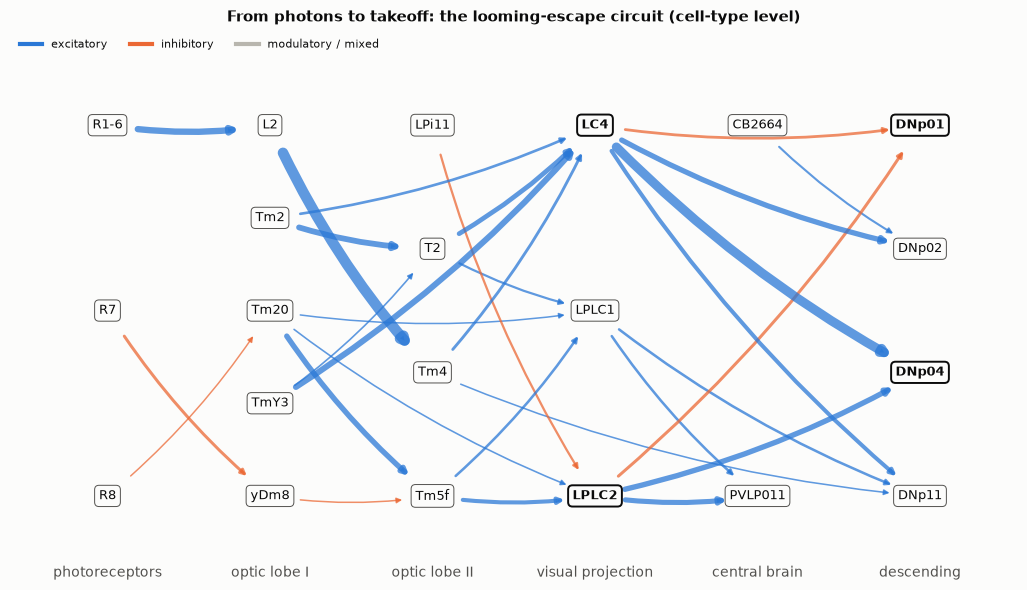

In [10]:
fig, ax = plt.subplots(figsize=(13, 6.5))
pp.plot_layered_circuit(layer, e, ax=ax, highlight={"LPLC2", "LC4", "DNp01", "DNp04"},
                        layer_names=[names[x] for x in sorted(set(layer.values()))])
ax.set_title("From photons to takeoff: the looming-escape circuit (cell-type level)", pad=28)
fig.savefig(FIGURES / "looming_escape_circuit.png")
plt.show()

## Part 2 — Every sense, every descending neuron

Now the brain-wide version: start from **all** sensory neurons and measure how far each neuron is.

In [11]:
sensory = an.select(ann, super_class=list(an.SENSORY_SUPER_CLASSES))
d_all = pw.hop_distance(g, sensory)
print(f"{len(sensory):,} sensory seeds; unreachable neurons: {(d_all == pw.UNREACHED).sum():,}")
pd.Series(d_all[dn]).value_counts().sort_index().rename("DNs").to_frame()

13,025 sensory seeds; unreachable neurons: 2,302


,DNs
-1,17
1,355
2,780
3,117
4,6
5,1


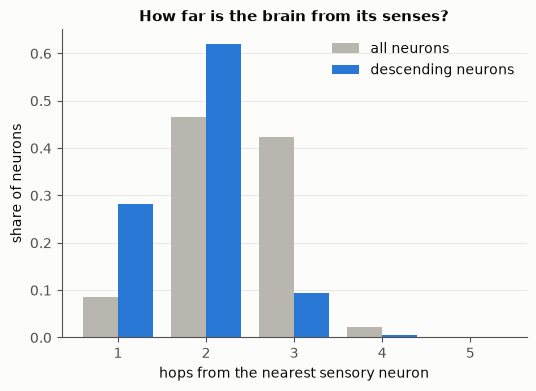

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
pp.plot_hop_histogram(d_all[d_all > 0], d_all[dn][d_all[dn] > 0], "descending neurons", ax=ax)
ax.set_title("How far is the brain from its senses?")
fig.savefig(FIGURES / "hops_from_sensory.png")
plt.show()

Almost every neuron is within 3 hops of *some* sensory neuron. Hubs make the brain a small world,
which is also why raw hop counts are a blunt instrument; the information-flow layers below fix that.

### Which senses reach the descending neurons fastest?
One BFS, one Dijkstra and one probabilistic traversal per modality.

In [13]:
modality = an.sensory_modality(ann)
dn_mask = np.zeros(g.n, bool); dn_mask[dn] = True
rows, hop_share, strength = [], {}, {}
for m in modality.dropna().unique():
    seeds = np.flatnonzero(modality.eq(m).fillna(False).to_numpy())
    d = pw.hop_distance(g, seeds)[dn]
    reached = d[d > 0]
    hop_share[m] = pd.Series(reached).value_counts(normalize=True)
    strength[m] = pw.strongest_paths(g, seeds, fractions=F).strength[dn]
    layer_m, _ = pw.information_flow(g, seeds, n_runs=64, fractions=F, seed=0)
    rows.append({"modality": m, "sensory neurons": len(seeds),
                 "DNs at 1 hop": (d == 1).mean(), "DNs within 2 hops": ((d >= 1) & (d <= 2)).mean(),
                 "mean hops": reached.mean(), "median info-flow layer": np.nanmedian(layer_m[dn])})
speed = pd.DataFrame(rows).set_index("modality").sort_values("mean hops")
speed.round(3)

,sensory neurons,DNs at 1 hop,DNs within 2 hops,mean hops,median info-flow layer
modality,,,,,
mechanosensory,1500,0.132,0.703,2.182,5.086
ascending_sensory,360,0.087,0.719,2.195,5.679
unknown_sensory,117,0.048,0.579,2.395,6.369
johnstons_organ,664,0.107,0.515,2.436,5.803
gustatory,333,0.023,0.290,2.949,6.730
thermosensory,29,0.002,0.096,3.151,7.214
olfactory,2170,0.001,0.088,3.252,6.637
hygrosensory,74,0.002,0.057,3.257,7.159
visual,7540,0.000,0.016,3.554,6.937


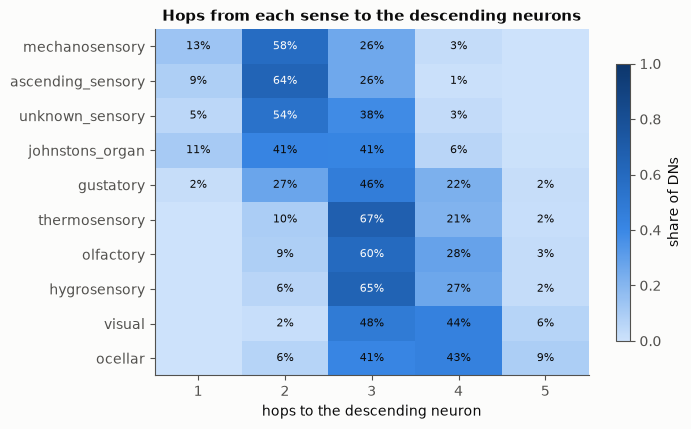

In [14]:
heat = pd.DataFrame(hop_share).T.reindex(speed.index).fillna(0)
heat.columns = heat.columns.astype(int)
heat = heat.reindex(columns=range(1, heat.columns.max() + 1), fill_value=0)
heat = heat.loc[:, heat.max() >= 0.005]   # drop hop counts no modality uses
fig, ax = plt.subplots(figsize=(7, 4.5))
pp.plot_modality_heatmap(heat, ax=ax)
ax.set_title("Hops from each sense to the descending neurons")
fig.savefig(FIGURES / "modality_hops_to_dns.png")
plt.show()

Touch and body sense (mechanosensory, Johnston's organ in the antenna, and the ascending sensory
neurons from the legs) are wired closest to the motor output: most DNs are two hops away, and over
a hundred get direct input. Vision, the largest sense by far, sits three to four hops out, behind
the optic lobes, which spend those layers turning pixels into features like "something is looming".

### Which sense dominates each DN?
For each DN, the modality whose strongest path into it is strongest.

In [17]:
S = pd.DataFrame(strength)
dominant = S.idxmax(axis=1)
dn_family = pd.Series(ct[dn]).str.extract(r"^(DN[a-z])")[0].fillna("other")
pd.crosstab(dn_family.to_numpy(), dominant.to_numpy(), margins=True,
            rownames=["DN family"], colnames=["dominant modality"])

dominant modality,ascending_sensory,gustatory,hygrosensory,johnstons_organ,mechanosensory,ocellar,olfactory,thermosensory,unknown_sensory,visual,All
DN family,,,,,,,,,,,
DNa,20,0,0,3,12,0,0,0,17,0,52
DNb,14,0,0,5,6,2,0,2,12,0,41
DNc,0,0,0,0,1,0,2,0,0,1,4
DNd,9,0,0,0,6,0,0,1,6,0,22
DNg,151,38,2,166,307,11,0,2,129,17,823
DNp,108,17,8,53,53,14,6,4,54,4,321
DNx,0,0,0,0,1,0,0,0,0,0,1
other,5,1,0,0,1,0,0,0,5,0,12
All,307,56,10,227,387,27,8,9,223,22,1276


### Probabilistic information-flow layers
The traversal model of Schlegel et al. (2021): a neuron passes the signal on with probability
min(1, input fraction / 0.3), and its layer is the average step at which it gets activated over many
random runs. A single weak synapse no longer makes a neuron look close.

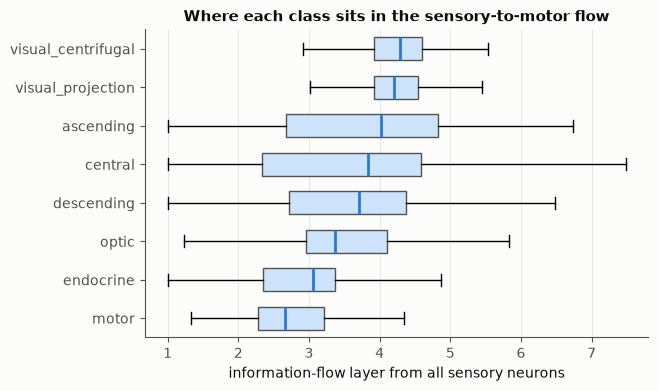

median layer of DNs: 3.71


In [16]:
layer_all, reach_all = pw.information_flow(g, sensory, n_runs=128, fractions=F, seed=0)
groups = ann["super_class"]
order = (pd.Series(layer_all).groupby(groups.to_numpy()).median()
           .drop(index=["sensory", "sensory_ascending"], errors="ignore").sort_values().index.tolist())
fig, ax = plt.subplots(figsize=(6.5, 4))
pp.plot_layer_by_group(pd.Series(layer_all), groups, order, ax=ax,
                       xlabel="information-flow layer from all sensory neurons")
ax.set_title("Where each class sits in the sensory-to-motor flow")
fig.savefig(FIGURES / "information_flow_layers.png")
plt.show()
print("median layer of DNs:", round(float(np.nanmedian(layer_all[dn])), 2))

## Takeaways

- **The pipeline recovers known biology unprompted.** LPLC2 and LC4, the looming detectors
  identified in electrophysiology, are the top two input types of both giant fibers
  (17% of the left one's input, 20% of the right's).
- **Escape is a population, not a single trigger.** DNp04 gets ~60% of its input from
  LPLC2/LC4, about three times the giant fiber's share, and DNp02 and DNp11 also get large
  shares. Looming feeds several output channels, which suggests graded escape choices.
- **Photons reach the giant fiber in 3 synapses.** At cell-type level the strongest route is
  R1-6 → L2 → Tm2 → LC4 → DNp01, all excitatory. At single-neuron level the strongest path
  skips T4/T5, because no single T4 edge is strong; populations matter.
- **The output layer sits close to the senses.** 90% of descending neurons are within 2 hops of
  some sensory neuron, and 28% get direct sensory input, versus 9% of all neurons.
- **Touch is wired closest to action, vision farthest.** Mechanosensory neurons reach 70% of DNs
  within 2 hops (13% directly). Photoreceptors reach 1.6% within 2 hops and none directly;
  the optic lobes spend those layers extracting features like "something is approaching".
- **Body sense dominates the output layer.** By strongest path, touch, antennal (Johnston's
  organ) and ascending body sensors are the dominant input for 921 of 1,276 DNs (72%).
  Vision dominates 22, smell 8.
- **Hops and flow layers can disagree.** Ocellar input reaches some DNs in 2 hops but has the
  deepest median flow layer (8.9): the short paths exist, but they carry small input
  fractions. Hop count alone overstates how directly a sense drives behaviour.
- **Limits.** This is static wiring: no spikes, timing or thresholds; electrical synapses are
  missing; transmitter signs are predictions. Phase 3 tests these paths with a spiking model.